In [3]:
import pandas as pd

for scenario in ["calm", "gust", "strong_gust"]:
    df = pd.read_csv(
        f"wind_results/original/{scenario}_flight.csv"
    )

    print(f"\n--- {scenario.upper()} ---")
    print("Number of rows:", len(df))
    print("Duration:", df["time"].iloc[-1])
    print("Starting position:", df[["x", "y", "z"]].iloc[0].values)
    print("Final position:", df[["x", "y", "z"]].iloc[-1].values)
    print("Minimum altitude:", df["z"].min())
    print("Maximum |Y|:", df["y"].abs().max())


--- CALM ---
Number of rows: 687
Duration: 6.869999999999898
Starting position: [6.51470843e-21 1.86084628e-20 3.02330522e-01]
Final position: [ 5.2369973  -0.02226078  1.01151788]
Minimum altitude: 0.3023305223969811
Maximum |Y|: 0.0240770404990129

--- GUST ---
Number of rows: 687
Duration: 6.869999999999898
Starting position: [6.51470843e-21 1.86084628e-20 3.02330522e-01]
Final position: [5.23783844 0.00927977 1.0115251 ]
Minimum altitude: 0.3023305223969811
Maximum |Y|: 0.0092797730605064

--- STRONG_GUST ---
Number of rows: 687
Duration: 6.869999999999898
Starting position: [6.51470843e-21 1.86084628e-20 3.02330522e-01]
Final position: [5.2386924  0.04082339 1.01152011]
Minimum altitude: 0.3023305223969811
Maximum |Y|: 0.0408233916995148


In [3]:
summary = pd.read_csv(
    "wind_results/experiment_summary.csv"
)

display(summary)

,scenario,success,crashed,flight_time,final_goal_error,maximum_lateral_deviation,minimum_altitude
0,calm,True,False,6.87,0.238319,0.024077,0.302331
1,gust,False,False,35.00,95.327243,73.238769,0.233223
2,strong_gust,False,False,35.00,56.179601,45.004959,0.302331


In [4]:
import mujoco

model = mujoco.MjModel.from_xml_path(
    "mujoco_menagerie-main/skydio_x2/scene.xml"
)

body_id = model.body("x2").id
print("Drone body mass:", model.body_mass[body_id], "kg")

Drone body mass: 1.325 kg


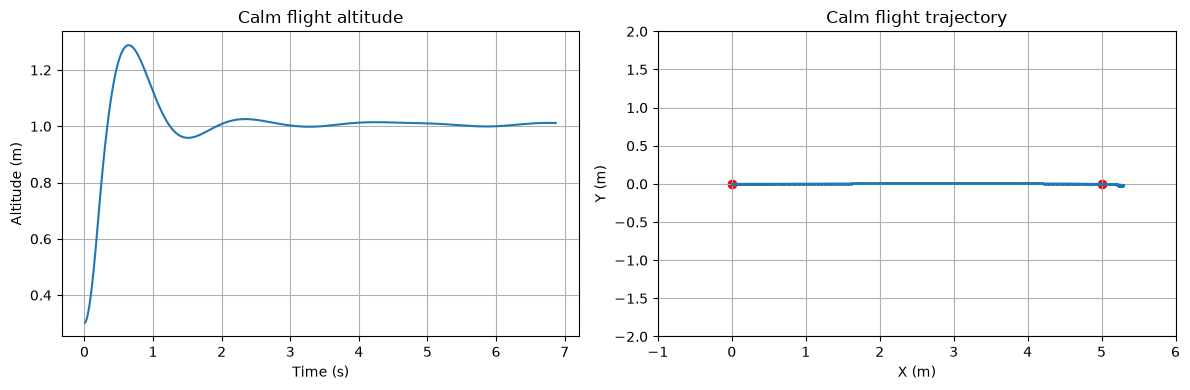

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

calm = pd.read_csv(
    "wind_results/calm_flight.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(calm["time"], calm["z"])
axes[0].set_title("Calm flight altitude")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Altitude (m)")
axes[0].grid(True)

axes[1].plot(calm["x"], calm["y"], marker=".", markersize=2)
axes[1].scatter([0, 5], [0, 0], color="red")
axes[1].set_title("Calm flight trajectory")
axes[1].set_xlabel("X (m)")
axes[1].set_ylabel("Y (m)")
axes[1].set_xlim(-1, 6)
axes[1].set_ylim(-2, 2)
axes[1].grid(True)

plt.tight_layout()
plt.show()

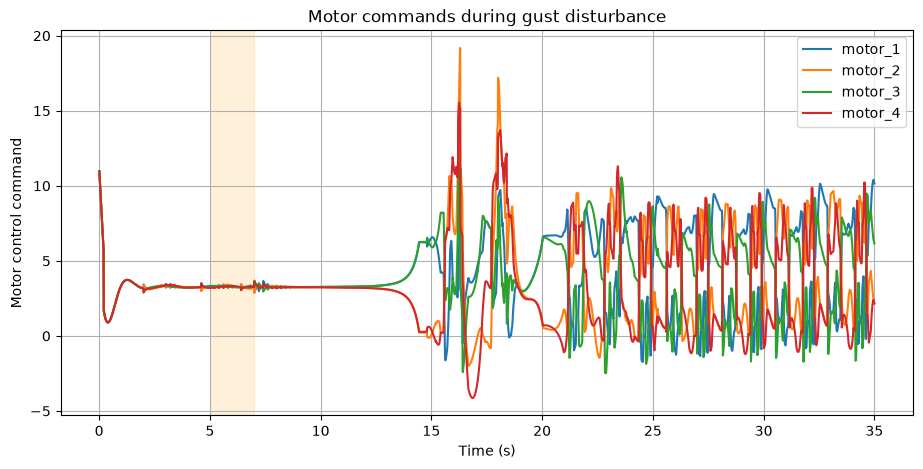

In [7]:
gust = pd.read_csv(
    "wind_results/gust_flight.csv"
)

plt.figure(figsize=(11, 5))

for motor in ["motor_1", "motor_2", "motor_3", "motor_4"]:
    plt.plot(gust["time"], gust[motor], label=motor)

plt.axvspan(5, 7, color="orange", alpha=0.15)
plt.xlabel("Time (s)")
plt.ylabel("Motor control command")c
plt.title("Motor commands during gust disturbance")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
import numpy as np

def motor_variation(df):
    motors = df[
        ["motor_1", "motor_2", "motor_3", "motor_4"]
    ].to_numpy()

    changes = np.diff(motors, axis=0)

    return np.mean(np.abs(changes))

for controller in ["original", "corrected"]:
    for scenario in ["calm", "gust", "strong_gust"]:
        df = pd.read_csv(
            f"wind_results/"
            f"{controller}/{scenario}_flight.csv"
        )

        print(
            controller,
            scenario,
            "Motor variation:",
            round(motor_variation(df), 5)
        )

original calm Motor variation: 0.02451
original gust Motor variation: 0.02452
original strong_gust Motor variation: 0.02452
corrected calm Motor variation: 0.00529
corrected gust Motor variation: 0.00519
corrected strong_gust Motor variation: 0.00511


In [8]:
controllers = ["original", "corrected"]
scenarios = ["calm", "gust", "strong_gust"]

results = []

for controller in controllers:
    for scenario in scenarios:

        path = (
            f"wind_results/"
            f"{controller}/{scenario}_flight.csv"
        )

        df = pd.read_csv(path)

        # Distance from desired horizontal path Y = 0
        lateral_rmse = np.sqrt(np.mean(df["y"] ** 2))

        # Maximum lateral deviation
        max_deviation = np.max(np.abs(df["y"]))

        # Altitude tracking error
        altitude_rmse = np.sqrt(
            np.mean((df["z"] - 1.0) ** 2)
        )

        # Motor command variation
        motors = df[
            ["motor_1", "motor_2", "motor_3", "motor_4"]
        ].to_numpy()

        motor_variation = np.mean(
            np.abs(np.diff(motors, axis=0))
        )

        # Average squared motor command
        control_effort = np.mean(motors ** 2)

        results.append({
            "controller": controller,
            "scenario": scenario,
            "lateral_rmse": lateral_rmse,
            "max_deviation": max_deviation,
            "altitude_rmse": altitude_rmse,
            "motor_variation": motor_variation,
            "control_effort": control_effort,
            "flight_time": df["time"].iloc[-1]
        })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,controller,scenario,lateral_rmse,max_deviation,altitude_rmse,motor_variation,control_effort,flight_time
0,original,calm,0.0087,0.0241,0.1226,0.0245,11.8757,6.87
1,original,gust,0.0035,0.0093,0.1226,0.0245,11.8756,6.87
2,original,strong_gust,0.0106,0.0408,0.1226,0.0245,11.8757,6.87
3,corrected,calm,0.0000,0.0000,0.0554,0.0053,10.8200,33.75
4,corrected,gust,0.0474,0.0697,0.0549,0.0052,10.8151,34.41
5,corrected,strong_gust,0.0945,0.1393,0.0544,0.0051,10.8108,35.00


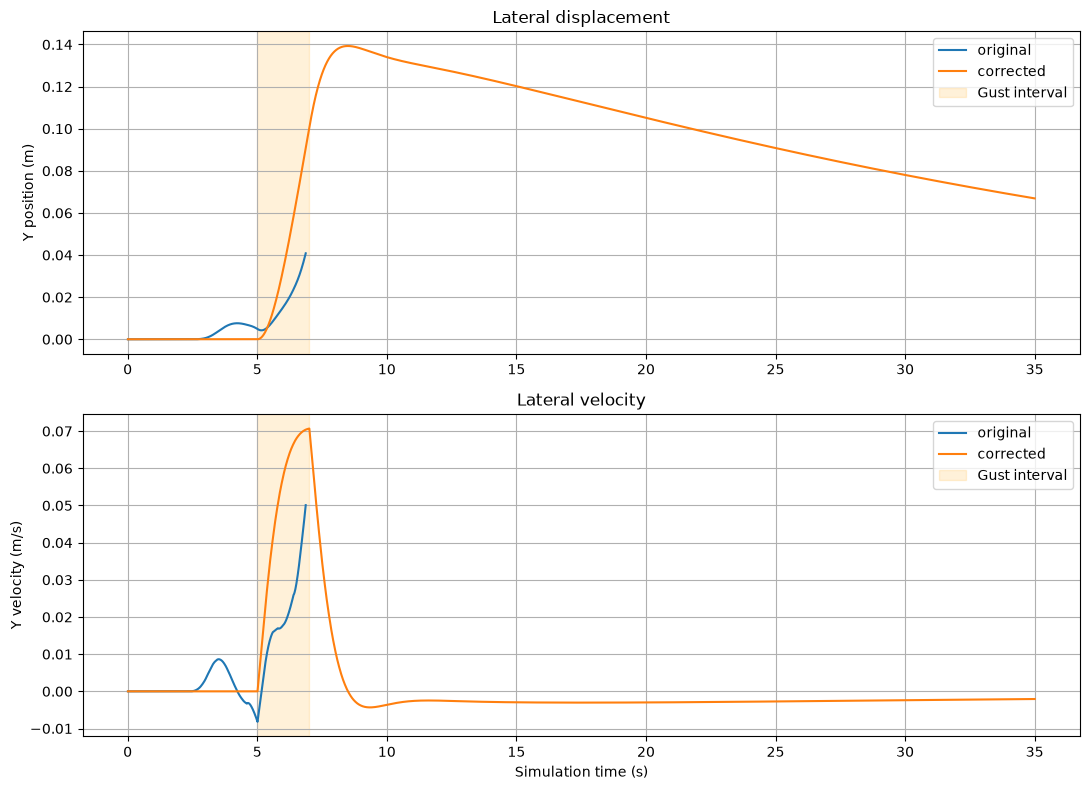

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

for controller in ["original", "corrected"]:
    df = pd.read_csv(
        f"wind_results/"
        f"{controller}/strong_gust_flight.csv"
    )

    axes[0].plot(
        df["time"],
        df["y"],
        label=controller
    )

    axes[1].plot(
        df["time"],
        df["vy"],
        label=controller
    )

for ax in axes:
    ax.axvspan(
        5, 7,
        color="orange",
        alpha=0.15,
        label="Gust interval"
    )
    ax.legend()
    ax.grid(True)

axes[0].set_title("Lateral displacement")
axes[0].set_ylabel("Y position (m)")

axes[1].set_title("Lateral velocity")
axes[1].set_ylabel("Y velocity (m/s)")
axes[1].set_xlabel("Simulation time (s)")

plt.tight_layout()
plt.show()


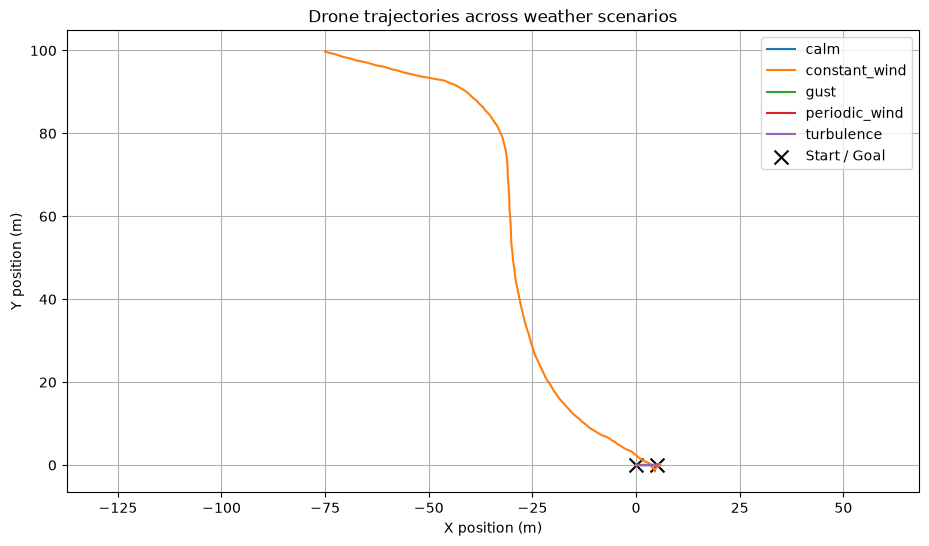

In [13]:
scenarios = [
    "calm",
    "constant_wind",
    "gust",
    "periodic_wind",
    "turbulence"
]

plt.figure(figsize=(11, 6))

for scenario in scenarios:
    df = pd.read_csv(
        f"wind_results/original/{scenario}_flight.csv"
    )

    plt.plot(df["x"], df["y"], label=scenario)

plt.scatter(
    [0, 5], [0, 0],
    color="black",
    marker="x",
    s=100,
    label="Start / Goal"
)

plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")
plt.title("Drone trajectories across weather scenarios")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

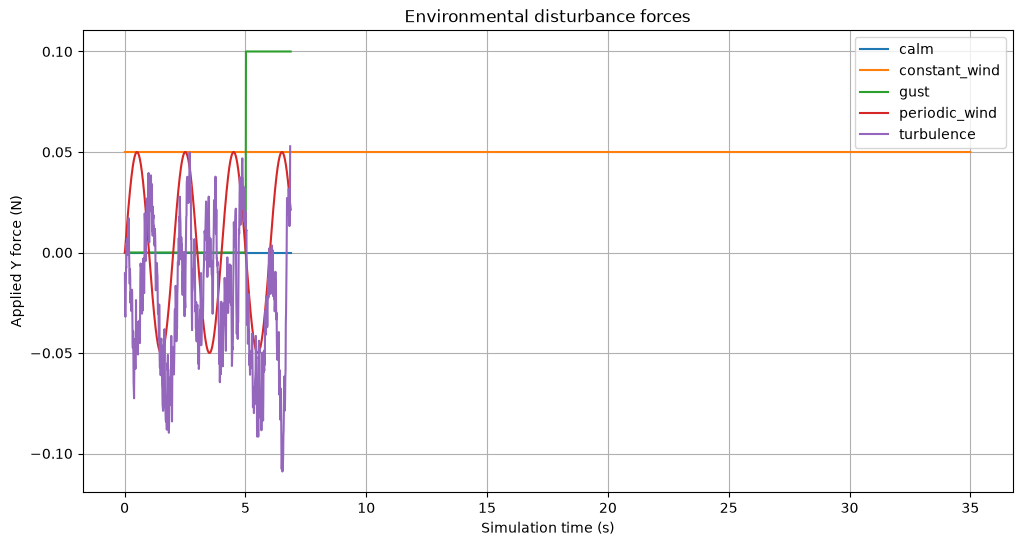

In [14]:
scenarios = [
    "calm",
    "constant_wind",
    "gust",
    "periodic_wind",
    "turbulence"
]

plt.figure(figsize=(12, 6))

for scenario in scenarios:
    df = pd.read_csv(
        f"wind_results/original/{scenario}_flight.csv"
    )

    plt.plot(
        df["time"],
        df["force_y"],
        label=scenario
    )

plt.xlabel("Simulation time (s)")
plt.ylabel("Applied Y force (N)")
plt.title("Environmental disturbance forces")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
scenarios = [
    "calm",
    "constant_wind",
    "gust",
    "periodic_wind",
    "turbulence"
]

results = []

for scenario in scenarios:
    df = pd.read_csv(
        f"wind_results/original/{scenario}_flight.csv"
    )

    results.append({
        "scenario": scenario,
        "flight_duration": df["time"].iloc[-1],
        "max_lateral_deviation": df["y"].abs().max(),
        "lateral_rmse": np.sqrt(np.mean(df["y"]**2)),
        "max_altitude": df["z"].max(),
        "min_altitude": df["z"].min(),
        "final_goal_error": np.linalg.norm(
            df[["x", "y", "z"]].iloc[-1].to_numpy()
            - np.array([5, 0, 1])
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,scenario,flight_duration,max_lateral_deviation,lateral_rmse,max_altitude,min_altitude,final_goal_error
0,calm,6.87,0.0241,0.0087,1.2881,0.3023,0.2383
1,constant_wind,35.00,99.7560,40.7230,1.2881,0.3023,127.8805
2,gust,6.87,0.0408,0.0106,1.2881,0.3023,0.2424
3,periodic_wind,6.87,0.0249,0.0113,1.2881,0.3023,0.2378
4,turbulence,6.85,0.0739,0.0314,1.2882,0.3023,0.2533


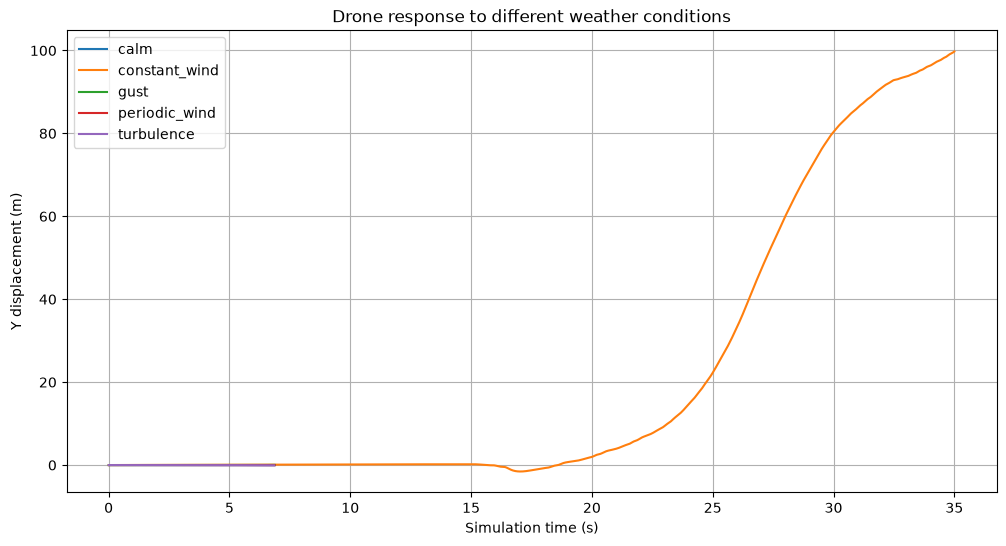

In [17]:
plt.figure(figsize=(12, 6))

for scenario in scenarios:
    df = pd.read_csv(
        f"wind_results/original/{scenario}_flight.csv"
    )

    plt.plot(
        df["time"],
        df["y"],
        label=scenario
    )

plt.xlabel("Simulation time (s)")
plt.ylabel("Y displacement (m)")
plt.title("Drone response to different weather conditions")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
import sys
sys.path.insert(0, "drone-example")

from weather import WeatherEnvironment
import numpy as np

weather1 = WeatherEnvironment("turbulence", seed=42)
weather2 = WeatherEnvironment("turbulence", seed=42)

forces1 = np.array([
    weather1.get_force(t * 0.01, dt=0.01)
    for t in range(1000)
])

forces2 = np.array([
    weather2.get_force(t * 0.01, dt=0.01)
    for t in range(1000)
])

print("Same seed produces same forces:",
      np.allclose(forces1, forces2))

Same seed produces same forces: True


In [19]:
scenarios = [
    "calm",
    "constant_wind",
    "gust",
    "periodic_wind",
    "turbulence"
]

results = []

for scenario in scenarios:
    df = pd.read_csv(
        f"wind_results/original/{scenario}_flight.csv"
    )

    results.append({
        "scenario": scenario,
        "flight_duration": df["time"].iloc[-1],
        "max_lateral_deviation": df["y"].abs().max(),
        "lateral_rmse": np.sqrt(np.mean(df["y"]**2)),
        "max_altitude": df["z"].max(),
        "min_altitude": df["z"].min(),
        "final_goal_error": np.linalg.norm(
            df[["x", "y", "z"]].iloc[-1].to_numpy()
            - np.array([5, 0, 1])
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,scenario,flight_duration,max_lateral_deviation,lateral_rmse,max_altitude,min_altitude,final_goal_error
0,calm,20.02,22.7869,7.0564,1.2881,0.1113,19.6429
1,constant_wind,22.32,32.8477,8.8540,2.0856,0.0869,36.9957
2,gust,19.35,19.1109,4.7936,1.3999,0.0845,24.8209
3,periodic_wind,19.46,17.3654,5.1928,1.2881,0.1090,14.6868
4,turbulence,23.60,42.4878,12.5471,1.6694,0.1093,48.3025


In [20]:
pd.read_csv(
        f"wind_results/original/experiment_summary.csv"
    )

,scenario,success,crashed,flight_time,final_goal_error,maximum_lateral_deviation,minimum_altitude,success_time
0,calm,True,True,20.02,19.642939,22.786900,0.111344,6.87
1,constant_wind,True,True,22.32,36.995715,32.847682,0.086890,6.87
2,gust,True,True,19.35,24.820851,19.110885,0.084483,6.87
3,periodic_wind,True,True,19.46,14.686841,17.365386,0.109049,6.87
4,turbulence,True,True,23.60,48.302544,42.487758,0.109274,6.85


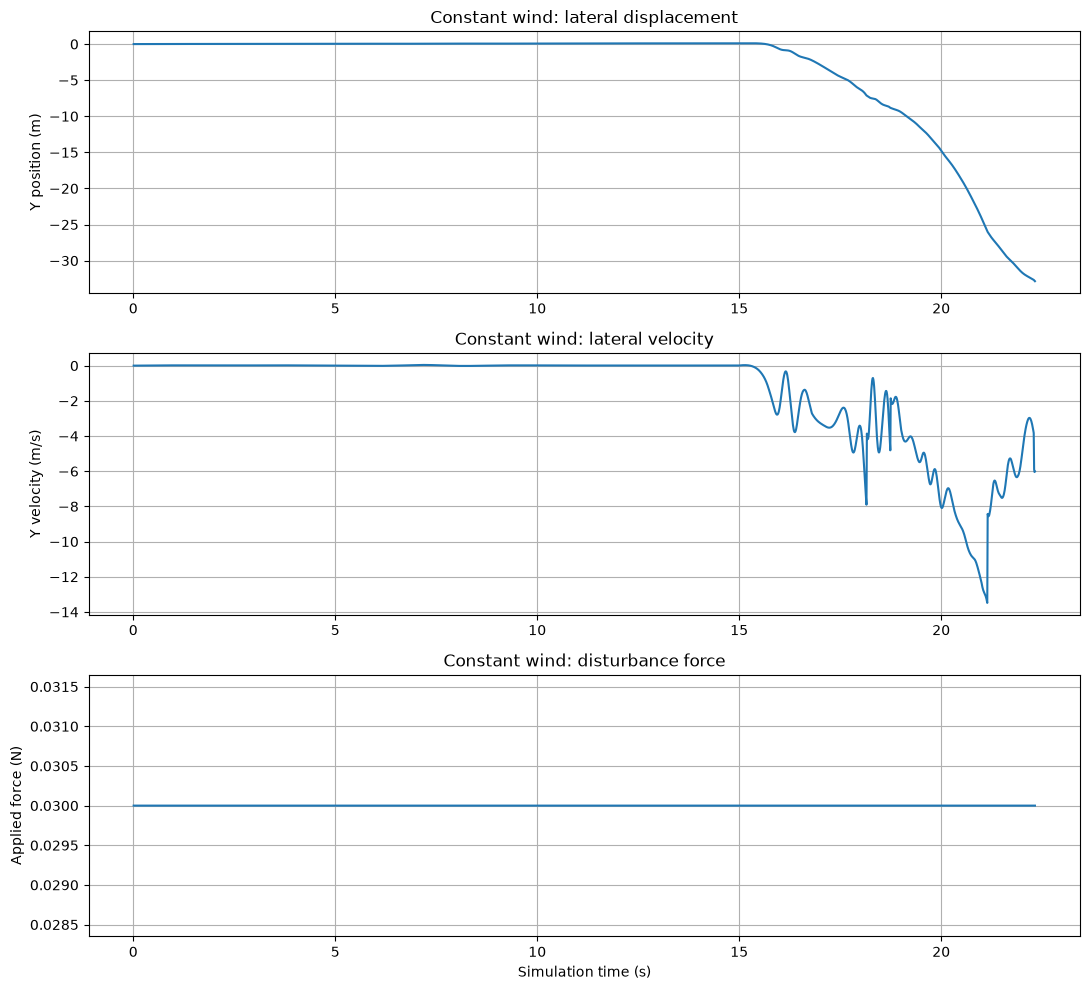

In [24]:
df = pd.read_csv(
    "wind_results/original/constant_wind_flight.csv"
)

fig, axes = plt.subplots(3, 1, figsize=(11, 10))

axes[0].plot(df["time"], df["y"])
axes[0].set_ylabel("Y position (m)")
axes[0].set_title("Constant wind: lateral displacement")

axes[1].plot(df["time"], df["vy"])
axes[1].set_ylabel("Y velocity (m/s)")
axes[1].set_title("Constant wind: lateral velocity")

axes[2].plot(df["time"], df["force_y"])
axes[2].set_ylabel("Applied force (N)")
axes[2].set_xlabel("Simulation time (s)")
axes[2].set_title("Constant wind: disturbance force")

for ax in axes:
    ax.grid(True)

plt.tight_layout()
plt.show()

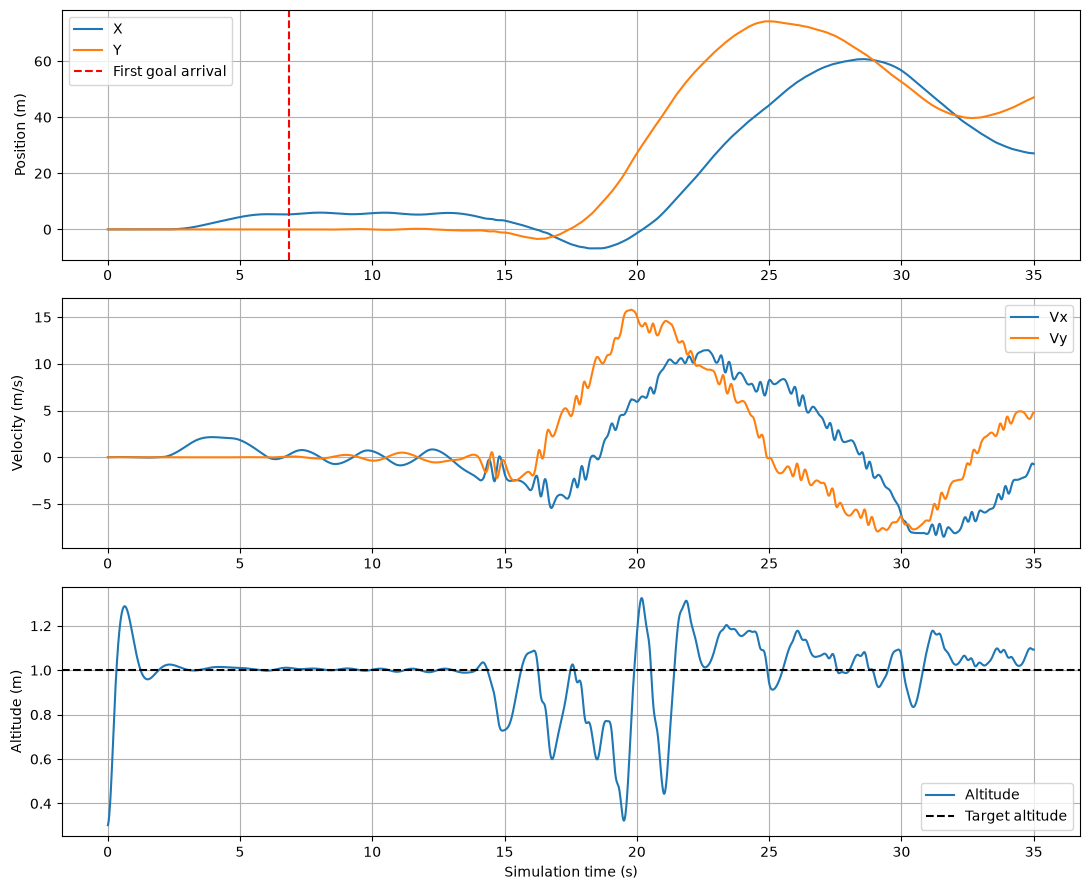

In [28]:
df = pd.read_csv(
    "wind_results/original/calm_flight.csv"
)

fig, axes = plt.subplots(3, 1, figsize=(11, 9))

axes[0].plot(df["time"], df["x"], label="X")
axes[0].plot(df["time"], df["y"], label="Y")
axes[0].axvline(6.87, color="red", linestyle="--",
                label="First goal arrival")
axes[0].set_ylabel("Position (m)")
axes[0].legend()

axes[1].plot(df["time"], df["vx"], label="Vx")
axes[1].plot(df["time"], df["vy"], label="Vy")
axes[1].set_ylabel("Velocity (m/s)")
axes[1].legend()

axes[2].plot(df["time"], df["z"], label="Altitude")
axes[2].axhline(1.0, color="black", linestyle="--",
                label="Target altitude")
axes[2].set_ylabel("Altitude (m)")
axes[2].set_xlabel("Simulation time (s)")
axes[2].legend()

for ax in axes:
    ax.grid(True)

plt.tight_layout()
plt.show()

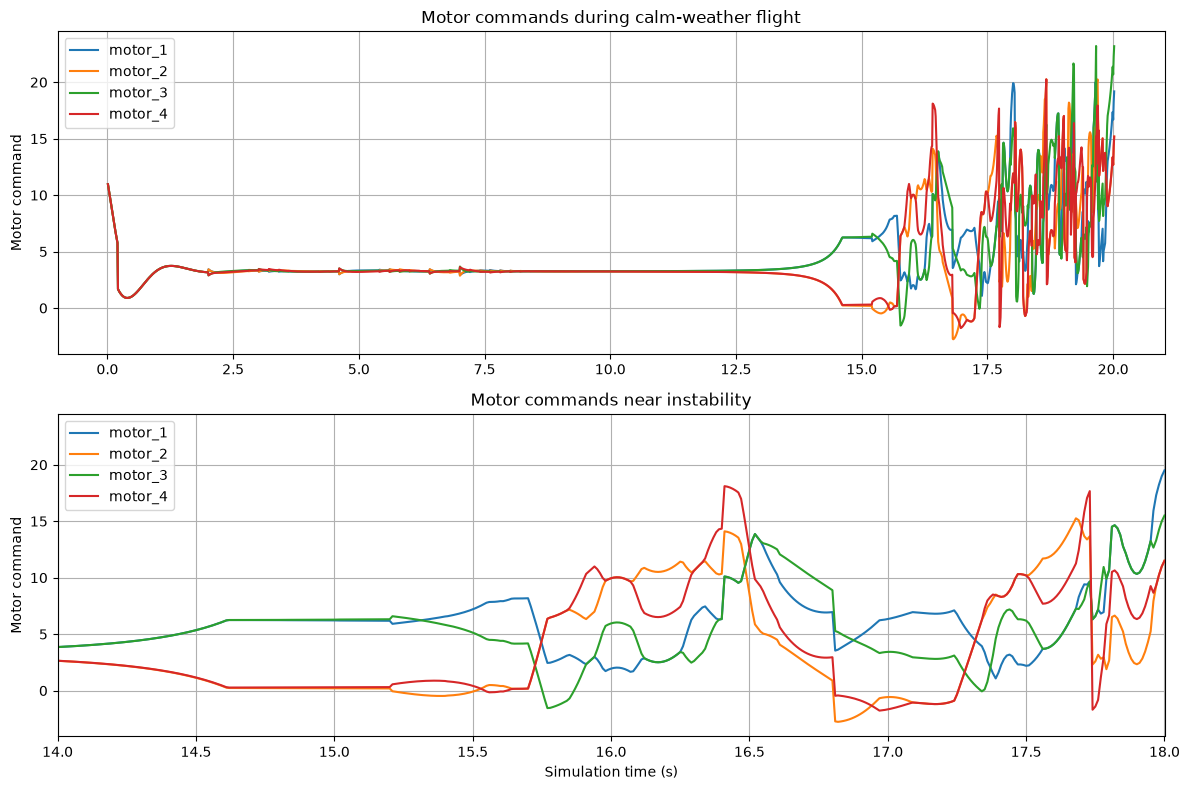

In [26]:
df = pd.read_csv(
    "wind_results/original/calm_flight.csv"
)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

motor_cols = [
    "motor_1", "motor_2", "motor_3", "motor_4"
]

for motor in motor_cols:
    axes[0].plot(df["time"], df[motor], label=motor)

axes[0].set_title("Motor commands during calm-weather flight")
axes[0].set_ylabel("Motor command")
axes[0].legend()
axes[0].grid(True)

for motor in motor_cols:
    axes[1].plot(df["time"], df[motor], label=motor)

axes[1].set_xlim(14, 18)
axes[1].set_title("Motor commands near instability")
axes[1].set_xlabel("Simulation time (s)")
axes[1].set_ylabel("Motor command")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [27]:
df = pd.read_csv(
    "wind_results/original/calm_flight.csv"
)

print("Maximum absolute external force:")
print(df[["force_x", "force_y", "force_z"]].abs().max())

print("All forces zero:",
      np.allclose(
          df[["force_x", "force_y", "force_z"]].to_numpy(),
          0
      ))

Maximum absolute external force:
force_x    0.0
force_y    0.0
force_z    0.0
dtype: float64
All forces zero: True


In [29]:
df = pd.read_csv(
    "wind_results/original/calm_flight.csv"
)

motors = ["motor_1", "motor_2", "motor_3", "motor_4"]

print(df[motors].agg(["min", "max", "mean"]))

print("\nMotor commands from 12 to 18 seconds:")
print(
    df.loc[
        df["time"].between(12, 18),
        ["time"] + motors
    ].iloc[::20].to_string(index=False)
)

        motor_1    motor_2    motor_3    motor_4
min   -2.816644  -1.952194  -2.557783  -3.144662
max   15.432330  14.460928  13.858121  16.698899
mean   3.929523   3.549736   3.978735   3.353197

Motor commands from 12 to 18 seconds:
 time   motor_1   motor_2   motor_3   motor_4
12.01  3.491790  2.686606  3.677869  3.619521
12.21  3.818234  2.941642  3.475418  3.080396
12.41  3.867455  2.743622  3.867107  2.560471
12.61  4.198700  2.304559  4.250695  2.196401
12.81  4.884321  1.647929  4.930862  1.618193
13.01  6.550523  0.566360  6.075350  0.114938
13.21  6.523869  0.553895  6.220147  0.190121
13.41  6.214328  0.150808  6.527869  0.591390
13.61  6.565528  0.261330  6.135647  0.439845
13.81  6.378400  1.144374  6.219818 -0.546156
14.01  6.049133  2.049133  6.049133 -1.950867
14.21  3.433932  4.850701  1.023358  3.261275
14.41  0.866568  4.866568  0.866568  8.866568
14.61 -0.486156  7.513844  3.513844  7.513844
14.81  4.315354  8.315354  0.315354  8.315354
15.01  7.315149  3.186902  4.